In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================
# 1. PARÂMETROS FINANCEIROS DE ENTRADA
# ==========================================
t_lifespan = 20           
r_discount = 0.065         
fuel_euro_per_L = 0.60    
carbon_euro_per_kgCO2 = 86.65/1e3    
rho = 0.95 
EFHFO = 3.15    
LHV = 11.25e3    
efficency_thermal = 0.36   
fuel_euro_per_kgHFO = fuel_euro_per_L / rho      

fuel_eWh_per_kgHFO = LHV * efficency_thermal #eletric energy per kg of HFO
fuel_euro_per_Wh = fuel_euro_per_kgHFO/fuel_eWh_per_kgHFO

fuel_eWh_per_kgCO2 = fuel_eWh_per_kgHFO / EFHFO
carbon_euro_per_Wh = carbon_euro_per_kgCO2 / fuel_eWh_per_kgCO2 # €/Wh


# Custos unitários da tecnologia (Ajusta com os custos do teu enunciado/grupo se diferirem)
capex_solar_per_MW = 900000.0       # €/MW
capex_wind_per_MW = 1400000.0       # €/MW
capex_hydro_per_MW = 2900000.0      # €/MW
capex_thermal_per_MW = 1200000.0     # €/MW

opex_solar_per_MW = 0.018 * capex_solar_per_MW         # €/MW/ano
opex_wind_per_MW = 0.025 * capex_wind_per_MW         # €/MW/ano
opex_hydro_per_MW = 0.03 * capex_hydro_per_MW        # €/MW/ano
opex_thermal_fixed_per_MW = 0.04 * capex_thermal_per_MW # €/MW/ano



# ==========================================
# 2. CAPACIDADES INSTALADAS E ENERGIA ANUAL
# ==========================================
# (Usa as variáveis já declaradas no teu notebook)
P_solar_MW = 10
P_wind_MW = 9.4
P_hydro_MW = 0.84
P_thermal_MW = 7.23
E_thermal_annual_MWh = 24241

# ==========================================
# 3. TABELA 14: CÁLCULO DE CAPEX E OPEX
# ==========================================
capex_vre_hydro = (P_solar_MW * capex_solar_per_MW + 
                   P_wind_MW * capex_wind_per_MW + 
                   P_hydro_MW * capex_hydro_per_MW)

capex_thermal = P_thermal_MW * capex_thermal_per_MW

first_year_opex = (P_solar_MW * opex_solar_per_MW +
                   P_wind_MW * opex_wind_per_MW +
                   P_hydro_MW * opex_hydro_per_MW +
                   P_thermal_MW * opex_thermal_fixed_per_MW +
                   E_thermal_annual_MWh * (fuel_euro_per_Wh + carbon_euro_per_Wh) * 1e6)


final_year_opex_yr20 = first_year_opex * ((1 + r_discount) ** 19)

table_14_df = pd.DataFrame({
    'Metric': ['Total VRE & Hydro CAPEX (€)', 'Thermal Backup CAPEX (€)', 'First-Year OPEX (€/year)', 'Final-Year OPEX (Year 20) (€/year)'],
    'Value': [capex_vre_hydro, capex_thermal, first_year_opex, final_year_opex_yr20]
})

print("--- TABELA 14: CAPEX & OPEX Assumptions ---")
display(table_14_df.round(2))



--- TABELA 14: CAPEX & OPEX Assumptions ---


,Metric,Value
0,Total VRE & Hydro CAPEX (€),24596000.00
1,Thermal Backup CAPEX (€),8676000.00
2,First-Year OPEX (€/year),6325101.63
3,Final-Year OPEX (Year 20) (€/year),20927148.49


In [51]:
total_capex = capex_vre_hydro + capex_thermal
total_opex = first_year_opex
solar_energy_annual_MWh = 20306
wind_energy_annual_MWh = 37321
hydro_energy_annual_MWh = 4578
solar_d = 0.005
wind_d = 0.01
hydro_d = 0.02
thermal_d = 0.03


# Vector de anos (1 a 20) e fatores de desconto NPV
years = np.arange(1, t_lifespan + 1)
discount_factors = (1 + r_discount) ** (-years)

# NPV dos Custos Totais (€)
npv_costs = total_capex + np.sum(total_opex * discount_factors)

# 4. Geração de Energia Anual com Degradação (MWh)
E_solar_t = solar_energy_annual_MWh * ((1 - solar_d) ** (years - 1))
E_wind_t = wind_energy_annual_MWh * ((1 - wind_d) ** (years - 1))
E_hydro_t = hydro_energy_annual_MWh * ((1 - hydro_d) ** (years - 1))
E_thermal_t = E_thermal_annual_MWh * ((1 - thermal_d) ** (years - 1))

E_total_t = E_solar_t + E_wind_t + E_hydro_t + E_thermal_t

# NPV da Energia Gerada (MWh)
npv_energy = np.sum(E_total_t * discount_factors)

# 5. Cálculo Final do LCOE (€/MWh)
lcoeA = npv_costs / npv_energy

print(f"Total CAPEX: {total_capex:,.2f} €")
print(f"OPEX Anual Total: {total_opex:,.2f} €/ano")
print(f"NPV dos Custos: {npv_costs:,.2f} €")
print(f"NPV da Energia: {npv_energy:,.2f} MWh")
print(f"LCOE: {lcoeA:.2f} €/MWh")

Total CAPEX: 33,272,000.00 €
OPEX Anual Total: 6,325,101.63 €/ano
NPV dos Custos: 102,965,178.18 €
NPV da Energia: 857,164.22 MWh
LCOE: 120.12 €/MWh


In [52]:
# ==========================================
# CENÁRIO BASELINE: 100% THERMAL POWER PLANT
# ==========================================

# 1. Energia anual total produzida pela central térmica (MWh)
E_thermal_baseline_annual_MWh = 67976.55

# Capacidade térmica instalada para o cenário baseline (MW)
# Assumindo P_thermal_MW = 7.23 MW (ou o pico total da procura, se diferente)
P_thermal_baseline_MW = 11.5  

# 2. CAPEX e OPEX do Cenário Baseline
capex_baseline = 0

# OPEX do 1º ano: OPEX Fixo da Térmica + Custo Variável (Combustível + Carbono) para 100% da energia
first_year_opex_baseline = (P_thermal_baseline_MW * opex_thermal_fixed_per_MW + 
                            E_thermal_baseline_annual_MWh * (fuel_euro_per_Wh + carbon_euro_per_Wh) * 1e6)

final_year_opex_baseline_yr20 = first_year_opex_baseline * ((1 + r_discount) ** 19)

# 3. Tabela 14 - Versão Baseline
table_14_baseline_df = pd.DataFrame({
    'Metric': ['Total VRE & Hydro CAPEX (€)', 'Thermal Backup CAPEX (€)', 'First-Year OPEX (€/year)', 'Final-Year OPEX (Year 20) (€/year)'],
    'Value': [0.0, capex_baseline, first_year_opex_baseline, final_year_opex_baseline_yr20]
})

print("--- TABELA 14: CAPEX & OPEX Assumptions (Baseline 100% HFO) ---")
display(table_14_baseline_df.round(2))

# 4. Cálculo do LCOE Baseline (€/MWh)
total_capex_baseline = capex_baseline
total_opex_baseline = first_year_opex_baseline

# NPV dos Custos Totais (€)
npv_costs_baseline = total_capex_baseline + np.sum(total_opex_baseline * discount_factors)

# Geração de Energia Anual com Degradação da Térmica (3% ao ano)
E_thermal_baseline_t = E_thermal_baseline_annual_MWh * ((1 - thermal_d) ** (years - 1))

# NPV da Energia Gerada (MWh)
npv_energy_baseline = np.sum(E_thermal_baseline_t * discount_factors)

# Cálculo Final do LCOE Baseline (€/MWh)
lcoe_baseline = npv_costs_baseline / npv_energy_baseline

print("\n--- RESULTADOS LCOE BASELINE (100% HFO) ---")
print(f"Total CAPEX Baseline: {total_capex_baseline:,.2f} €")
print(f"OPEX Anual Total Baseline: {total_opex_baseline:,.2f} €/ano")
print(f"NPV dos Custos Baseline: {npv_costs_baseline:,.2f} €")
print(f"NPV da Energia Baseline: {npv_energy_baseline:,.2f} MWh")
print(f"LCOE Baseline (100% HFO): {lcoe_baseline:.2f} €/MWh")

--- TABELA 14: CAPEX & OPEX Assumptions (Baseline 100% HFO) ---


,Metric,Value
0,Total VRE & Hydro CAPEX (€),0.00
1,Thermal Backup CAPEX (€),0.00
2,First-Year OPEX (€/year),15733873.40
3,Final-Year OPEX (Year 20) (€/year),52056887.64



--- RESULTADOS LCOE BASELINE (100% HFO) ---
Total CAPEX Baseline: 0.00 €
OPEX Anual Total Baseline: 15,733,873.40 €/ano
NPV dos Custos Baseline: 173,363,798.10 €
NPV da Energia Baseline: 605,114.93 MWh
LCOE Baseline (100% HFO): 286.50 €/MWh


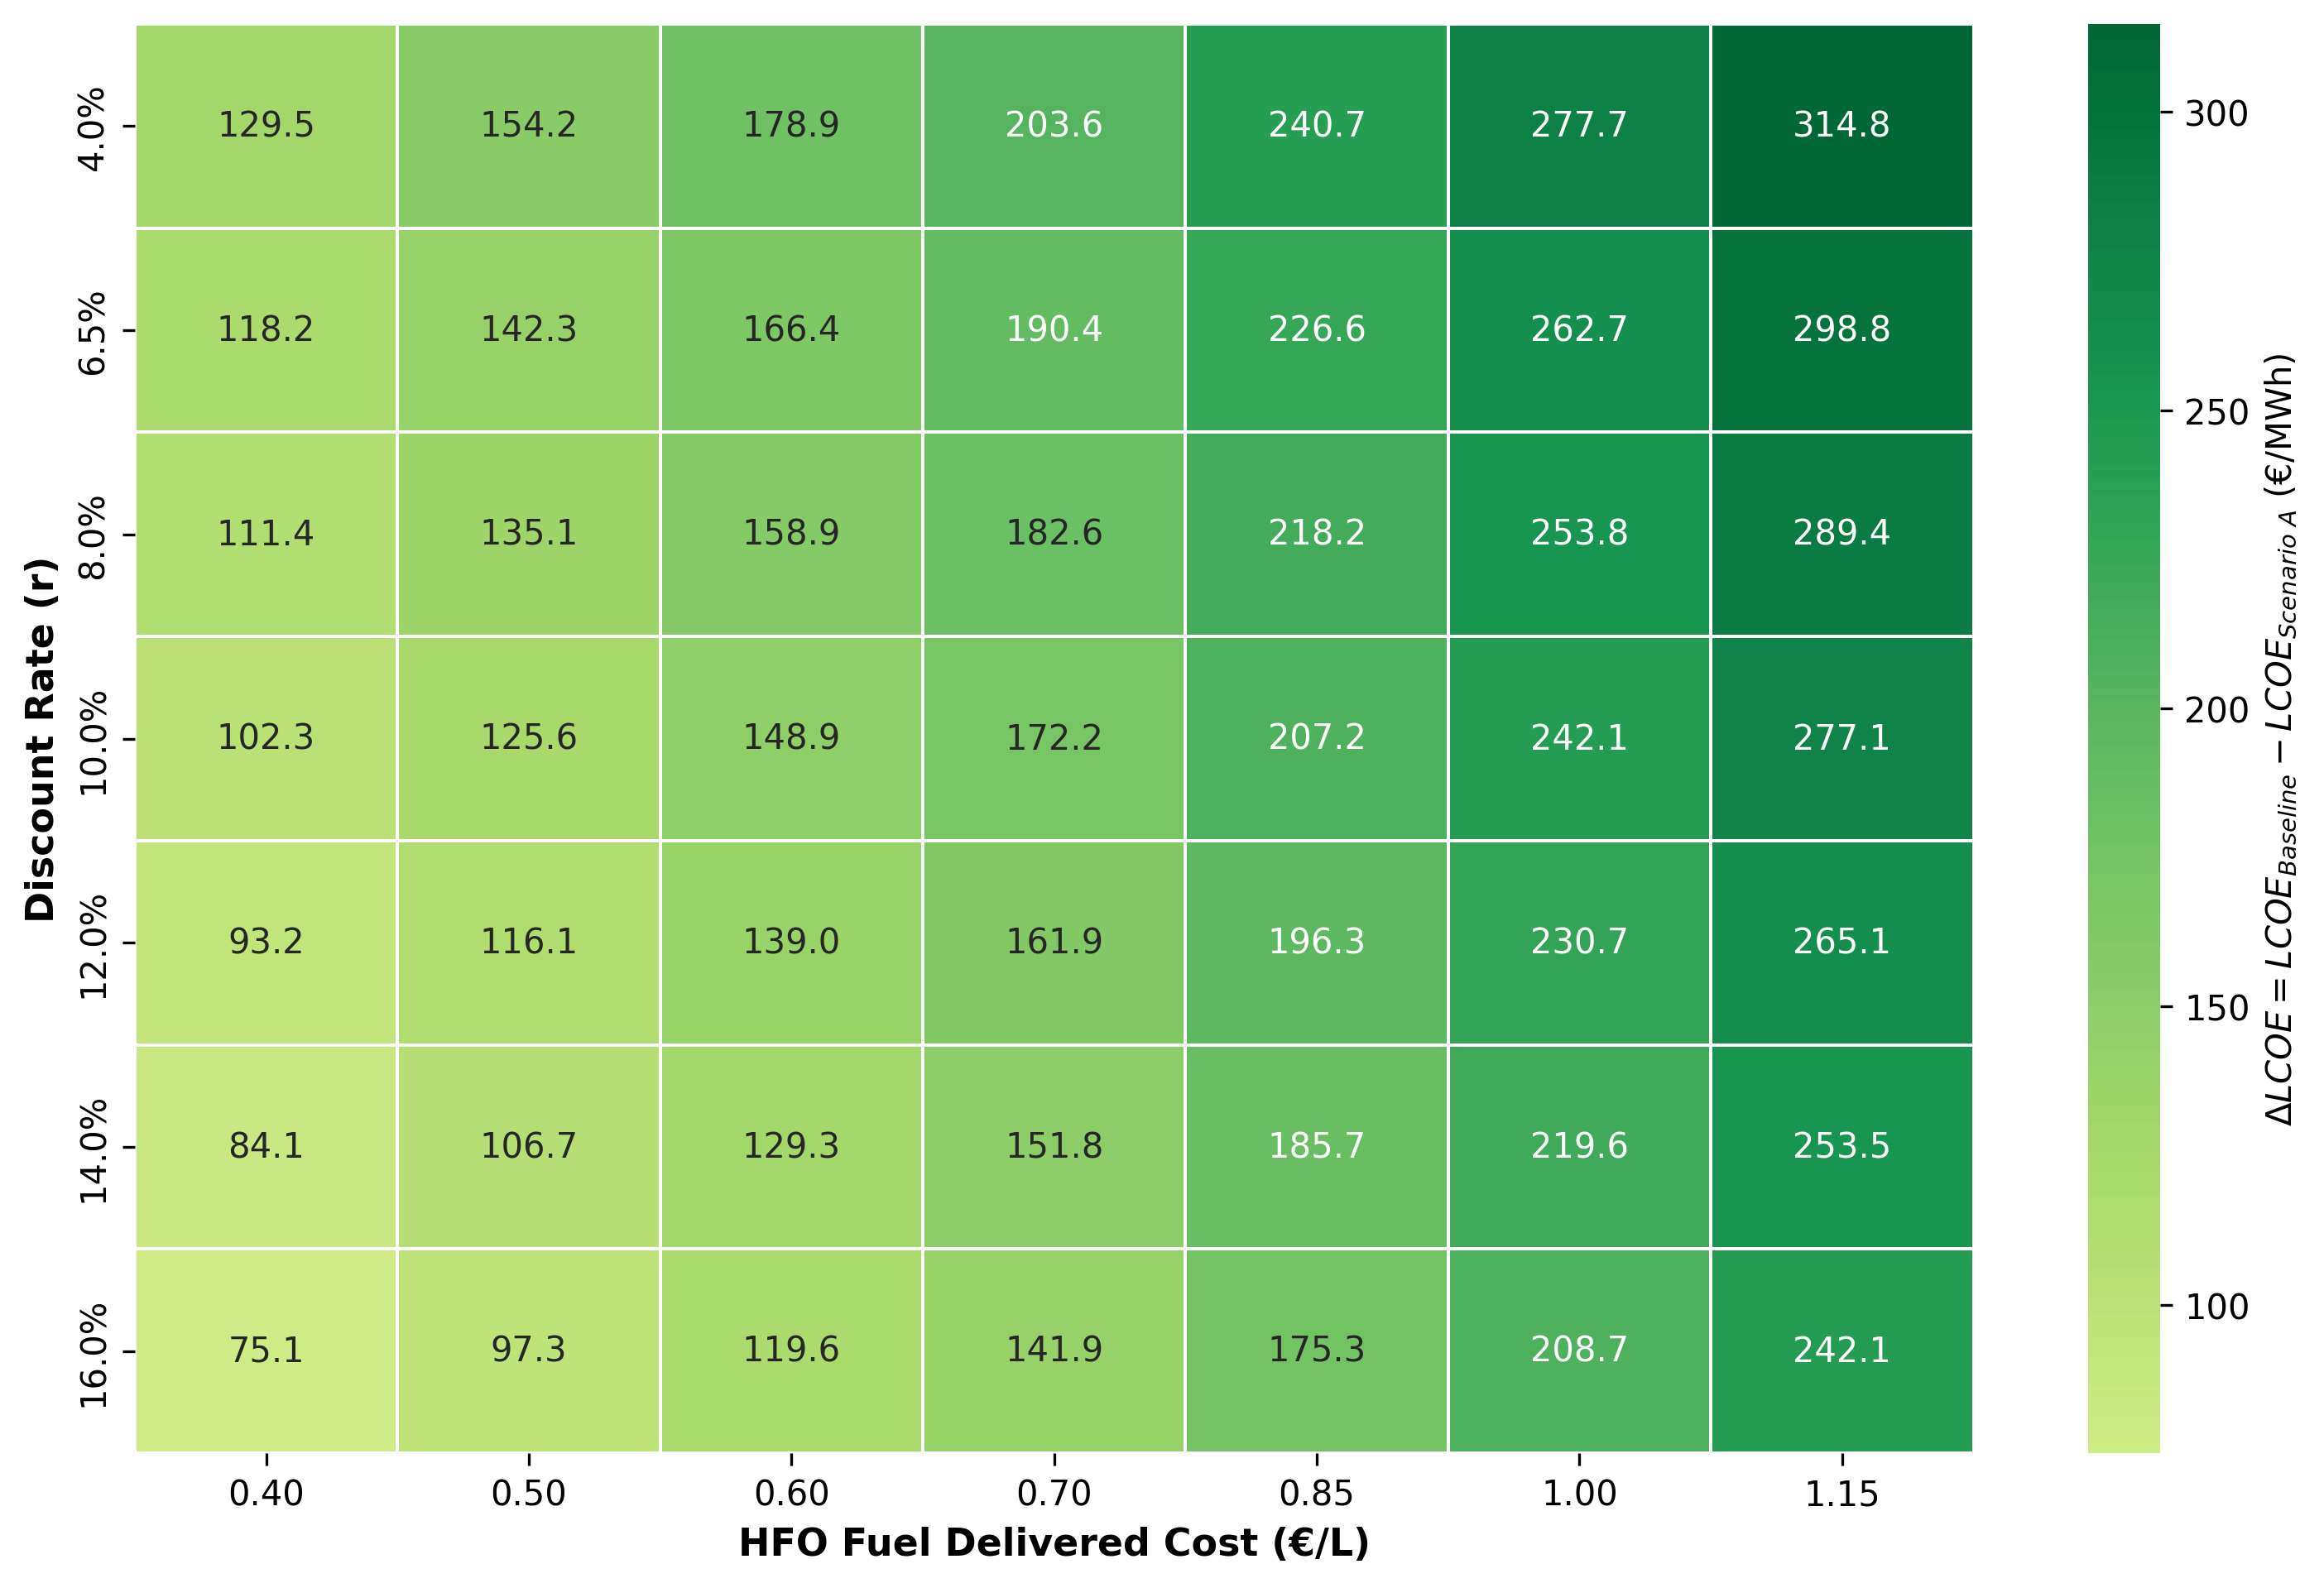

In [53]:
# ==========================================
# FUNÇÕES QUE DEPENDEM APENAS DE (r, fuel_price)
# ==========================================

def get_lcoe_scenario_a(r, fuel_price):
    """Calcula o LCOE do Cenário A (Híbrido) dependendo apenas de r e fuel_price."""
    df_factors = (1 + r) ** (-years)
    
    # Preço do combustível e taxa de carbono em €/Wh
    f_kg = fuel_price / rho
    f_Wh = f_kg / fuel_eWh_per_kgHFO
    var_cost_wh = f_Wh + carbon_euro_per_Wh
    
    # NPV dos Custos
    fixed_opex_A = (P_solar_MW * opex_solar_per_MW + P_wind_MW * opex_wind_per_MW +
                    P_hydro_MW * opex_hydro_per_MW + P_thermal_MW * opex_thermal_fixed_per_MW)
    var_opex_A = E_thermal_annual_MWh * var_cost_wh * 1e6
    npv_costs_A = (capex_vre_hydro + capex_thermal) + np.sum((fixed_opex_A + var_opex_A) * df_factors)
    
    # NPV da Energia (com degradação)
    E_solar_t = solar_energy_annual_MWh * ((1 - solar_d) ** (years - 1))
    E_wind_t = wind_energy_annual_MWh * ((1 - wind_d) ** (years - 1))
    E_hydro_t = hydro_energy_annual_MWh * ((1 - hydro_d) ** (years - 1))
    E_thermal_t = E_thermal_annual_MWh * ((1 - thermal_d) ** (years - 1))
    npv_energy_A = np.sum((E_solar_t + E_wind_t + E_hydro_t + E_thermal_t) * df_factors)
    
    return npv_costs_A / npv_energy_A


def get_lcoe_baseline(r, fuel_price):
    """Calcula o LCOE do Cenário Baseline (100% HFO) dependendo apenas de r e fuel_price."""
    df_factors = (1 + r) ** (-years)
    
    # Preço do combustível e taxa de carbono em €/Wh
    f_kg = fuel_price / rho
    f_Wh = f_kg / fuel_eWh_per_kgHFO
    var_cost_wh = f_Wh + carbon_euro_per_Wh
    
    # NPV dos Custos (Central Legada sem novo CAPEX)
    fixed_opex_base = P_thermal_baseline_MW * opex_thermal_fixed_per_MW
    var_opex_base = E_thermal_baseline_annual_MWh * var_cost_wh * 1e6
    npv_costs_base = capex_baseline + np.sum((fixed_opex_base + var_opex_base) * df_factors)
    
    # NPV da Energia
    E_thermal_baseline_t = E_thermal_baseline_annual_MWh * ((1 - thermal_d) ** (years - 1))
    npv_energy_base = np.sum(E_thermal_baseline_t * df_factors)
    
    return npv_costs_base / npv_energy_base


def get_delta_lcoe(r, fuel_price):
    """Retorna a diferença ΔLCOE = LCOE_Baseline - LCOE_ScenarioA."""
    return get_lcoe_baseline(r, fuel_price) - get_lcoe_scenario_a(r, fuel_price)


# ==========================================
# GERAÇÃO DA MATRIZ DE SENSIBILIDADE (FIGURA 7)
# ==========================================

discount_rates = np.array([0.04, 0.065, 0.08, 0.10, 0.12, 0.14, 0.16])
fuel_prices = np.array([0.40, 0.50, 0.60, 0.70, 0.85, 1.00, 1.15])

# Construir a matriz aplicando a função diretamente sobre cada par (r, fuel_price)
delta_lcoe_matrix = np.array([[get_delta_lcoe(r, f) for f in fuel_prices] for r in discount_rates])

# Desenhar a Figura 7 com Seaborn
plt.figure(figsize=(10, 6.5), dpi=300)

sns.heatmap(
    delta_lcoe_matrix, 
    annot=True, 
    fmt=".1f", 
    cmap="RdYlGn", 
    center=0,
    linewidths=0.5, 
    cbar_kws={'label': r'$\Delta LCOE = LCOE_{Baseline} - LCOE_{Scenario\ A}$ (€/MWh)'},
    xticklabels=[f"{f:.2f}" for f in fuel_prices],
    yticklabels=[f"{r*100:.1f}%" for r in discount_rates]
)

plt.xlabel('HFO Fuel Delivered Cost (€/L)', fontsize=11, fontweight='bold')
plt.ylabel('Discount Rate (r)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_7_sensitivity.png')
plt.show()

In [54]:
P_solar_B = 5
P_hydro_B = 0.84
P_wind_B = 4.7
P_thermal_B = 11.5

E_solar_B = 10153.99
E_hydro_B = 4577.55
E_wind_B = 18660.29
E_thermal_annual_MWh = 38901.19


capex_vre_hydro_B = (P_solar_B * capex_solar_per_MW + 
                   P_wind_B * capex_wind_per_MW + 
                   P_hydro_B * capex_hydro_per_MW)

capex_thermal_B = 0

first_year_opex_B = (P_solar_B * opex_solar_per_MW +
                   P_wind_B * opex_wind_per_MW +
                   P_hydro_B * opex_hydro_per_MW +
                   P_thermal_B * opex_thermal_fixed_per_MW)


total_capex = capex_vre_hydro_B + capex_thermal_B
total_fixed_opex = first_year_opex_B
variable_opex = E_thermal_annual_MWh * (fuel_euro_per_Wh + carbon_euro_per_Wh) * 1e6
total_opex = total_fixed_opex + variable_opex




# Vector de anos (1 a 20) e fatores de desconto NPV
years = np.arange(1, t_lifespan + 1)
discount_factors = (1 + r_discount) ** (-years)

# NPV dos Custos Totais (€)
npv_costs = total_capex + np.sum(total_opex * discount_factors)

# 4. Geração de Energia Anual com Degradação (MWh)
E_solar_t = solar_energy_annual_MWh * ((1 - solar_d) ** (years - 1))
E_wind_t = wind_energy_annual_MWh * ((1 - wind_d) ** (years - 1))
E_hydro_t = hydro_energy_annual_MWh * ((1 - hydro_d) ** (years - 1))
E_thermal_t = E_thermal_annual_MWh * ((1 - thermal_d) ** (years - 1))

E_total_t = E_solar_t + E_wind_t + E_hydro_t + E_thermal_t

# NPV da Energia Gerada (MWh)
npv_energy = np.sum(E_total_t * discount_factors)

# 5. Cálculo Final do LCOE (€/MWh)
lcoeB = npv_costs / npv_energy

print(f"Total CAPEX: {total_capex:,.2f} €")
print(f"OPEX Anual Total: {total_opex:,.2f} €/ano")
print(f"NPV dos Custos: {npv_costs:,.2f} €")
print(f"NPV da Energia: {npv_energy:,.2f} MWh")
print(f"LCOE: {lcoeB:.2f} €/MWh")

Total CAPEX: 13,516,000.00 €
OPEX Anual Total: 9,558,766.47 €/ano
NPV dos Custos: 118,839,337.59 €
NPV da Energia: 987,666.58 MWh
LCOE: 120.32 €/MWh


In [55]:
dlcoe = lcoeB-lcoeA

print(f"Delta LCOE (A-B): {dlcoe:.2f} €/MWh")

Delta LCOE (A-B): 0.20 €/MWh
